1. setup

In [1]:
import os
import pandas as pd
from qiime2 import Visualization
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
raw_dir = '../data/raw'
data_dir = '../data/processed_ignored'
vis_dir = '../data/processed'

In [3]:
! ls

'Alpha Diversity.ipynb'		   'Taxonomic Classification.ipynb'
'Clustering closed ref ITS.ipynb'   Taxonomic_Classification_jingxi.ipynb
 Clustering.ipynb		    denoise.ipynb
'Quality Filtering.ipynb'	    denoise_cutprimer_notcut27.ipynb
'Quality plot generation.ipynb'     gwendolin_data_summary.ipynb
 Setup.ipynb			    try_taxanomy.ipynb


2. import data

In [4]:
! ls -l $raw_dir

total 2185760
-rw-r--r-- 1 jovyan jovyan  230686720 Oct 14 10:23 ITS_database.fasta
-rw-r--r-- 1 jovyan jovyan 1294892168 Oct 14 10:30 UNITE_public_19.02.2025.fasta
-rw-r--r-- 1 jovyan jovyan  712595535 Oct  2 15:24 fungut_forward_reads.qza
-rw-r--r-- 1 jovyan jovyan      18798 Oct  2 15:18 fungut_metadata.tsv


In [5]:
! echo 'Number of files in the directory is:' && ls $raw_dir| wc -l

Number of files in the directory is:
4


In [6]:
!unzip -l ../data/raw/fungut_forward_reads.qza | grep fastq | head -10

  6218883  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327540_01_L001_R1_001.fastq.gz
  2734350  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327531_01_L001_R1_001.fastq.gz
  3907977  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327266_01_L001_R1_001.fastq.gz
  5596947  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327415_01_L001_R1_001.fastq.gz
  4274543  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327489_01_L001_R1_001.fastq.gz
  1981961  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327284_01_L001_R1_001.fastq.gz
  4617752  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327464_01_L001_R1_001.fastq.gz
  4880282  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327562_01_L001_R1_001.fastq.gz
  3780841  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327513_01_L001_R1_001.fastq.gz
  4387898  2024-09-10 14:52   3638611

In [7]:
!unzip -l ../data/raw/fungut_forward_reads.qza | grep -c fastq.gz

150


In [8]:
metadata_df = pd.read_csv(f'{raw_dir}/fungut_metadata.tsv', sep='\t', index_col=0)
metadata_df.sample(n=5)

,country_sample,state_sample,latitude_sample,longitude_sample,sex_sample,age_years_sample,height_cm_sample,weight_kg_sample,bmi_sample,diet_type_sample,ibd_sample,gluten_sample
ID,,,,,,,,,,,,
ERR5327498,United Kingdom,Not provided,51.5,-0.3,female,50.0,164.0,63.0,23.61,Omnivore,I do not have this condition,I do not eat gluten because it makes me feel bad
ERR5327322,Australia,ACT,-35.3,149.1,male,68.0,183.0,70.0,20.9,Omnivore,I do not have this condition,No
ERR5327517,USA,MA,42.3,-72.6,male,71.0,167.0,92.0,32.93,Omnivore,I do not have this condition,No
ERR5327443,Not provided,Not provided,Not provided,Not provided,male,45.0,196.0,108.0,28.11,Omnivore but do not eat red meat,I do not have this condition,No
ERR5327450,United Kingdom,Not provided,50.4,-3.7,female,67.0,162.0,54.0,20.77,Vegetarian but eat seafood,I do not have this condition,No


3. check qc

In [9]:
!qiime tools peek ../data/raw/fungut_forward_reads.qza

!qiime demux summarize \
  --i-data ../data/raw/fungut_forward_reads.qza \
  --o-visualization ../data/processed/demux_summary.qzv

UUID:        3638611d-1767-413b-9390-70ee3d78e4ff
Type:        SampleData[SequencesWithQuality]
Data format: SingleLanePerSampleSingleEndFastqDirFmt
Saved Visualization to: ../data/processed/demux_summary.qzv


In [10]:
Visualization.load(f"{vis_dir}/demux_summary.qzv")

<visualization: Visualization uuid: 1eaa4d37-3991-4506-b2bb-506b81a79c24>

In [11]:
!qiime tools export \
  --input-path ../data/raw/fungut_forward_reads.qza \
  --output-path ../data/processed_ignored/exported

Exported ../data/raw/fungut_forward_reads.qza as SingleLanePerSampleSingleEndFastqDirFmt to directory ../data/processed_ignored/exported


checking the forward and reverse primer & visualization

In [13]:
%%bash
cd ../data/processed_ignored/exported
out=..
echo -e "sample\ttotal\twith_primer\tFWD\tFWD_rc\tREV" > $out/primer_counts.tsv
echo -e "sample\tposition\treads"                     > $out/primer_positions.tsv

for f in *.fastq.gz; do
  s=${f%%_*}
  zcat $f | awk -v s=$s -v out=$out '
    NR%4==2 {  # only read the sequence line
      n++
      p=index($0,"GCATCGATGAAGAACGCAGC"); if(p>0){h++; pos[p]++}
      if(index($0,"CTTGGTCATTTAGAGGAAGTAA")) a++
      if(index($0,"TTACTTCCTCTAAATGACCAAG")) b++
      if(index($0,"GCTGCGTTCTTCATCGATGC"))   c++
    }
    END {
      print s"\t"n"\t"h+0"\t"a+0"\t"b+0"\t"c+0 >> out"/primer_counts.tsv" #if find one, add 1; if cant find， then 0
      for(k in pos) print s"\t"k"\t"pos[k] >> out"/primer_positions.tsv"
    }'
done

echo "Reads with other primer orientations (all samples, expected ~0):"
awk -F'\t' 'NR>1{a+=$4; b+=$5; c+=$6} END{print "FWD:",a,"  FWD_rc:",b,"  REV:",c}' $out/primer_counts.tsv
true

Reads with other primer orientations (all samples, expected ~0):
FWD: 0   FWD_rc: 0   REV: 0


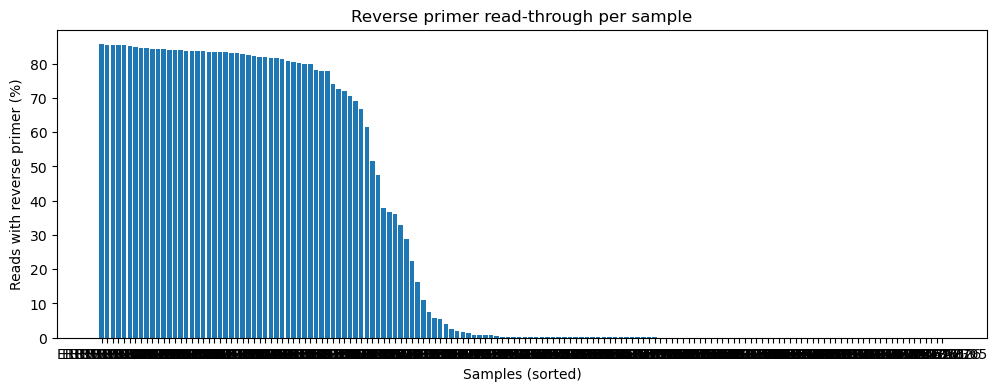

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

#read
counts = pd.read_csv(f'{data_dir}/primer_counts.tsv', sep='\t')

# count the percentage of reads contain primer in each sample
counts['percent'] = counts['with_primer'] / counts['total'] * 100

# from highest to lowest
counts = counts.sort_values('percent', ascending=False)

# bar plot
plt.figure(figsize=(12, 4))
plt.bar(counts['sample'], counts['percent'])                      
plt.xlabel('Samples (sorted)')
plt.ylabel('Reads with reverse primer (%)')
plt.title('Reverse primer read-through per sample')
plt.savefig(f'{vis_dir}/primer_percent_per_sample.png', dpi=200)
plt.show()

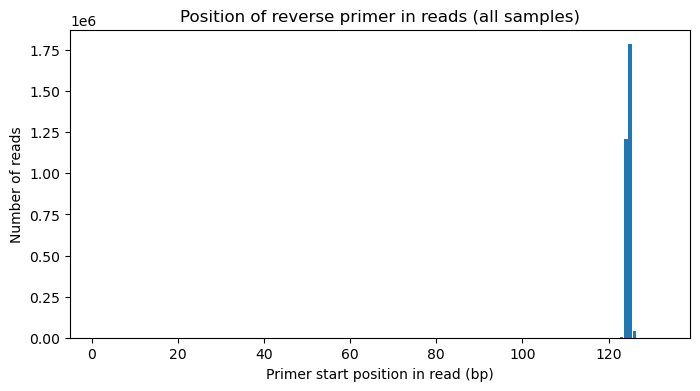

In [15]:
# read
pos = pd.read_csv(f'{data_dir}/primer_positions.tsv', sep='\t')

# find the counts in every position 
pos_total = pos.groupby('position')['reads'].sum()

# bar plot
plt.figure(figsize=(8, 4))
plt.bar(pos_total.index, pos_total.values)
plt.xlabel('Primer start position in read (bp)')
plt.ylabel('Number of reads')
plt.title('Position of reverse primer in reads (all samples)')
plt.savefig(f'{vis_dir}/primer_position.png', dpi=200)
plt.show()

4. cut the primer

In [16]:
%%bash
qiime cutadapt trim-single \
  --i-demultiplexed-sequences ../data/raw/fungut_forward_reads.qza \
  --p-adapter GCATCGATGAAGAACGCAGC \
  --p-minimum-length 50 \
  --p-cores 1 \
  --o-trimmed-sequences ../data/processed_ignored/reads_trimmed.qza \
  --o-stats ../data/processed_ignored/cutadapt_stats.qza

Saved SampleData[SequencesWithQuality] to: ../data/processed_ignored/reads_trimmed.qza
Saved ImmutableMetadata to: ../data/processed_ignored/cutadapt_stats.qza


quality plot after cut: The shortest read after trimming was 113 nt, and almost no reads were discarded.also the quality still looks good.

In [17]:
%%bash
qiime demux summarize \
  --i-data ../data/processed_ignored/reads_trimmed.qza \
  --o-visualization ../data/processed/reads_trimmed_summary.qzv

Saved Visualization to: ../data/processed/reads_trimmed_summary.qzv


In [18]:
Visualization.load(f'{vis_dir}/reads_trimmed_summary.qzv')

<visualization: Visualization uuid: 626c8fd2-ea90-4715-8521-ca62d655cf3e>

check how much we cut 

In [19]:
%%bash
qiime metadata tabulate \
  --m-input-file ../data/processed_ignored/cutadapt_stats.qza \
  --o-visualization ../data/processed/cutadapt_stats.qzv

Saved Visualization to: ../data/processed/cutadapt_stats.qzv


In [20]:
Visualization.load(f'{vis_dir}/cutadapt_stats.qzv')

<visualization: Visualization uuid: 2982d30e-348a-4b8e-b7bb-a24293e5fbd4>

5. denoise

In [21]:
!qiime dada2 denoise-single \
  --i-demultiplexed-seqs ../data/processed_ignored/reads_trimmed.qza \
  --p-trunc-len 0 \
  --p-n-threads 3 \
  --o-table ../data/processed_ignored/dada2_table.qza \
  --o-representative-sequences ../data/processed_ignored/dada2_rep_set.qza \
  --o-denoising-stats ../data/processed_ignored/dada2_stats.qza\
  --o-base-transition-stats ../data/processed_ignored/dada2_base_transition_stats.qza 

Saved FeatureTable[Frequency] to: ../data/processed_ignored/dada2_table.qza
Saved FeatureData[Sequence] to: ../data/processed_ignored/dada2_rep_set.qza
Saved SampleData[DADA2Stats] to: ../data/processed_ignored/dada2_stats.qza
Saved DADA2BaseTransitionStats to: ../data/processed_ignored/dada2_base_transition_stats.qza


In [22]:
!qiime metadata tabulate \
  --m-input-file ../data/processed_ignored/dada2_stats.qza \
  --o-visualization ../data/processed/dada2_stats.qzv

Saved Visualization to: ../data/processed/dada2_stats.qzv


In [23]:
from qiime2 import Visualization
Visualization.load("../data/processed/dada2_stats.qzv")

<visualization: Visualization uuid: cda596a8-044a-48c1-8da5-fcb7d2a847ea>

In [24]:
!qiime feature-table tabulate-seqs \
  --i-data ../data/processed_ignored/dada2_rep_set.qza \
  --o-visualization ../data/processed/dada2_rep_set.qzv

Saved Visualization to: ../data/processed/dada2_rep_set.qzv


In [25]:
Visualization.load("../data/processed/dada2_rep_set.qzv")

<visualization: Visualization uuid: 97822020-12ad-44cf-8466-f13a885e629a>

In [26]:
!qiime feature-table summarize \
  --i-table ../data/processed_ignored/dada2_table.qza \
  --m-metadata-file ../data/raw/fungut_metadata.tsv \
  --o-feature-frequencies ../data/processed_ignored/dada2_table_feature_frequencies.qza \
  --o-sample-frequencies ../data/processed_ignored/dada2_table_sample_frequencies.qza \
  --o-summary ../data/processed/dada2_table.qzv

Saved ImmutableMetadata to: ../data/processed_ignored/dada2_table_feature_frequencies.qza
Saved ImmutableMetadata to: ../data/processed_ignored/dada2_table_sample_frequencies.qza
Saved Visualization to: ../data/processed/dada2_table.qzv


In [27]:
Visualization.load("../data/processed/dada2_table.qzv")

<visualization: Visualization uuid: 3f2bd6ca-1905-4321-b6ea-f1daef5817c3>

check primer again

In [28]:
from qiime2 import Artifact
import pandas as pd

seqs = Artifact.load('../data/processed_ignored/dada2_rep_set.qza').view(pd.Series).astype(str)
print('Total ASVs:', len(seqs))
print('ASVs with reverse primer:', seqs.str.contains('GCATCGATGAAGAACGCAGC').sum())

Total ASVs: 681
ASVs with reverse primer: 0
